In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV
import shap

In [2]:
train=pd.read_csv('./train_dataset.txt',sep='\t').set_index('isoform')
test=pd.read_csv('./test_dataset.txt',sep='\t').set_index('isoform')

In [3]:
x_train = np.array(train.iloc[:,1:])
y_train = (np.array(train.iloc[:,0]))
x_test = np.array(test.iloc[:,1:])
y_test = (np.array(test.iloc[:,0]))

In [4]:
param_dist = {
    'learning_rate': [0.03],
    'n_estimators': [500],
    'max_depth': np.arange(1,11,step=1),
    'min_samples_split': np.arange(20,51,step=1),
    'min_samples_leaf': np.arange(1,21,step=1),
    'max_features': np.arange(1,16,step=1)
}
model = GradientBoostingRegressor(random_state=42)
random_search = RandomizedSearchCV(
    model, param_distributions=param_dist, n_iter=50, cv=5, n_jobs=40, scoring='neg_root_mean_squared_error',random_state=42
)
random_search.fit(x_train, y_train)
print("Best Parameters:", random_search.best_params_)

Best Parameters: {'n_estimators': 500, 'min_samples_split': 44, 'min_samples_leaf': 1, 'max_features': 15, 'max_depth': 9, 'learning_rate': 0.03}


In [5]:
model = random_search.best_estimator_
model.fit(x_train, y_train)

GradientBoostingRegressor(learning_rate=0.03, max_depth=9, max_features=15,
                          min_samples_split=44, n_estimators=500,
                          random_state=42)

In [6]:
joblib.dump(random_search.best_estimator_, "untrained_model.pkl")
joblib.dump(model, "trained_model.pkl")

['trained_model.pkl']

Text(0.5, 0, 'Feature importance based on mean decrease in impurity')

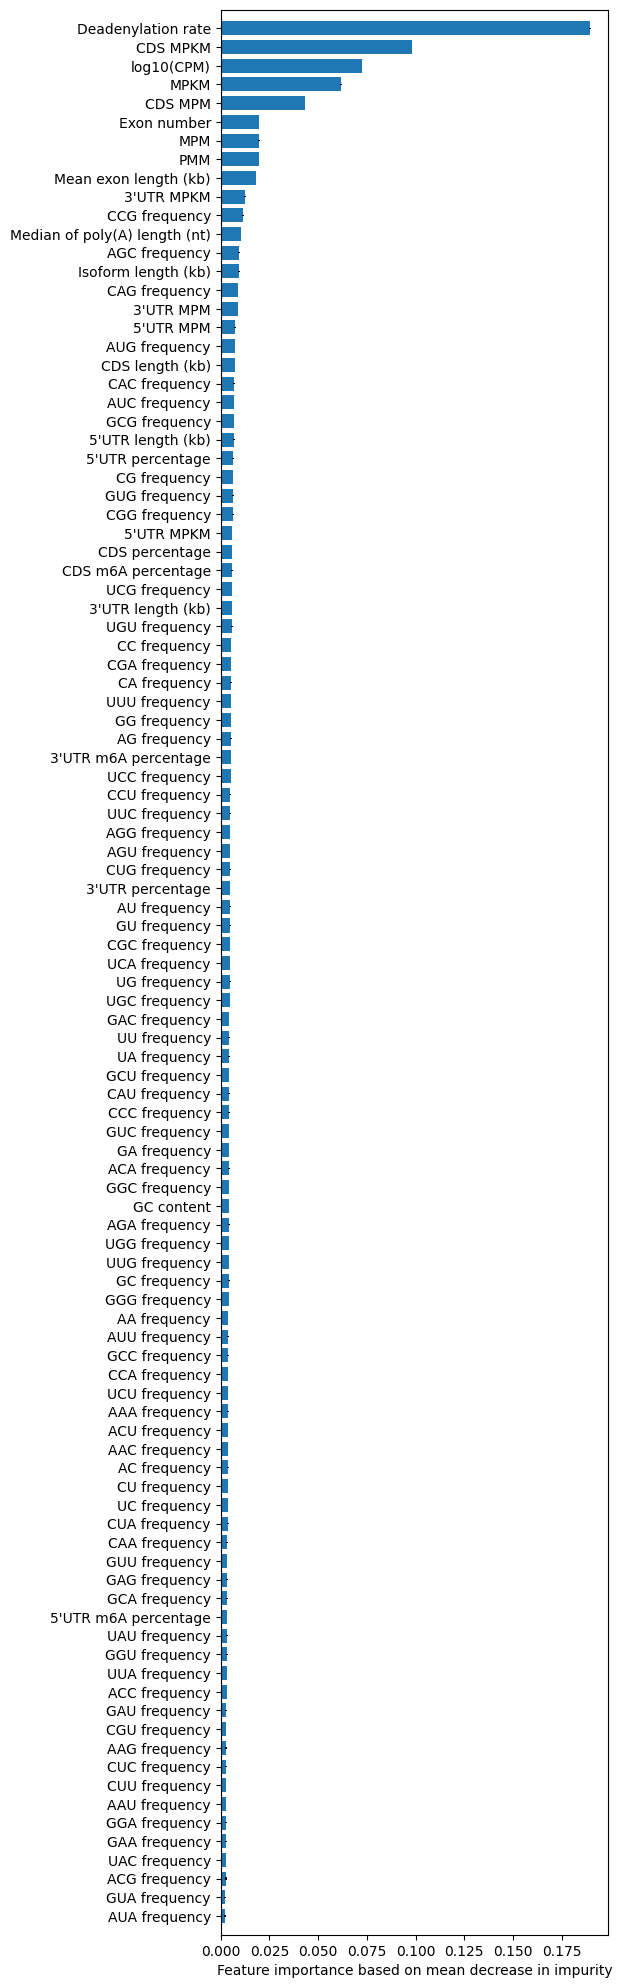

In [7]:
plt.figure(figsize=(5,25))
sorted_indices = np.argsort(model.feature_importances_)
std = np.std([tree[0].feature_importances_ for tree in model.estimators_], axis=0)
plt.barh(train.columns[1:][sorted_indices],model.feature_importances_[sorted_indices],height=0.75,yerr=std)
plt.ylim(bottom=-1,top=102)
plt.yticks(fontsize=10)
plt.xlabel('Feature importance based on mean decrease in impurity')

In [8]:
impurity_importance=pd.DataFrame()
impurity_importance['Feature']=train.columns[1:][sorted_indices]
impurity_importance['Importance']=model.feature_importances_[sorted_indices]
impurity_importance['Std']=std
impurity_importance.to_csv('./impurity_importance.txt',sep='\t',index=False)

In [9]:
def validate_plot(model,x,y):
    from scipy.stats import pearsonr
    from scipy.stats import gaussian_kde
    from sklearn.metrics import r2_score
    y_pred = model.predict(x)
    corr, p_value = pearsonr(y_pred, y)
    r2 = r2_score(y, y_pred)
    xy = np.vstack([y, y_pred])
    density = gaussian_kde(xy)(xy)
    plt.figure(figsize=(4,3))
    scatter=  plt.scatter(y,y_pred,s=10, c=density, cmap='coolwarm')
    plt.xlabel('True decay rate')
    plt.ylabel('Predicted decay rate')
    plt.xlim(-0.14,1.14)
    plt.ylim(-0.14,1.14)
    plt.yticks(np.arange(-0.1,1.11,step=0.2))
    plt.xticks(np.arange(-0.1,1.11,step=0.2))
    plt.text(s=f'Pearson\'s r: {round(corr,3)}',y=0.95,x=-0.1)
    plt.plot([-0.1,1.1],[-0.1,1.1],c='red',ls='--',label='y = x')
    cbar=plt.colorbar(scatter,label='KDE density')
    plt.legend(frameon=False)

Text(0.5, 0, 'Permutation Importance')

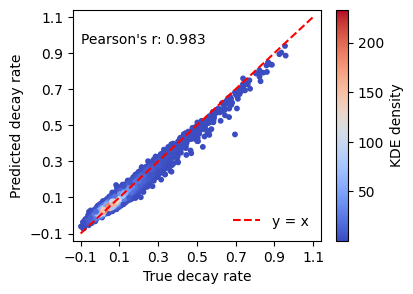

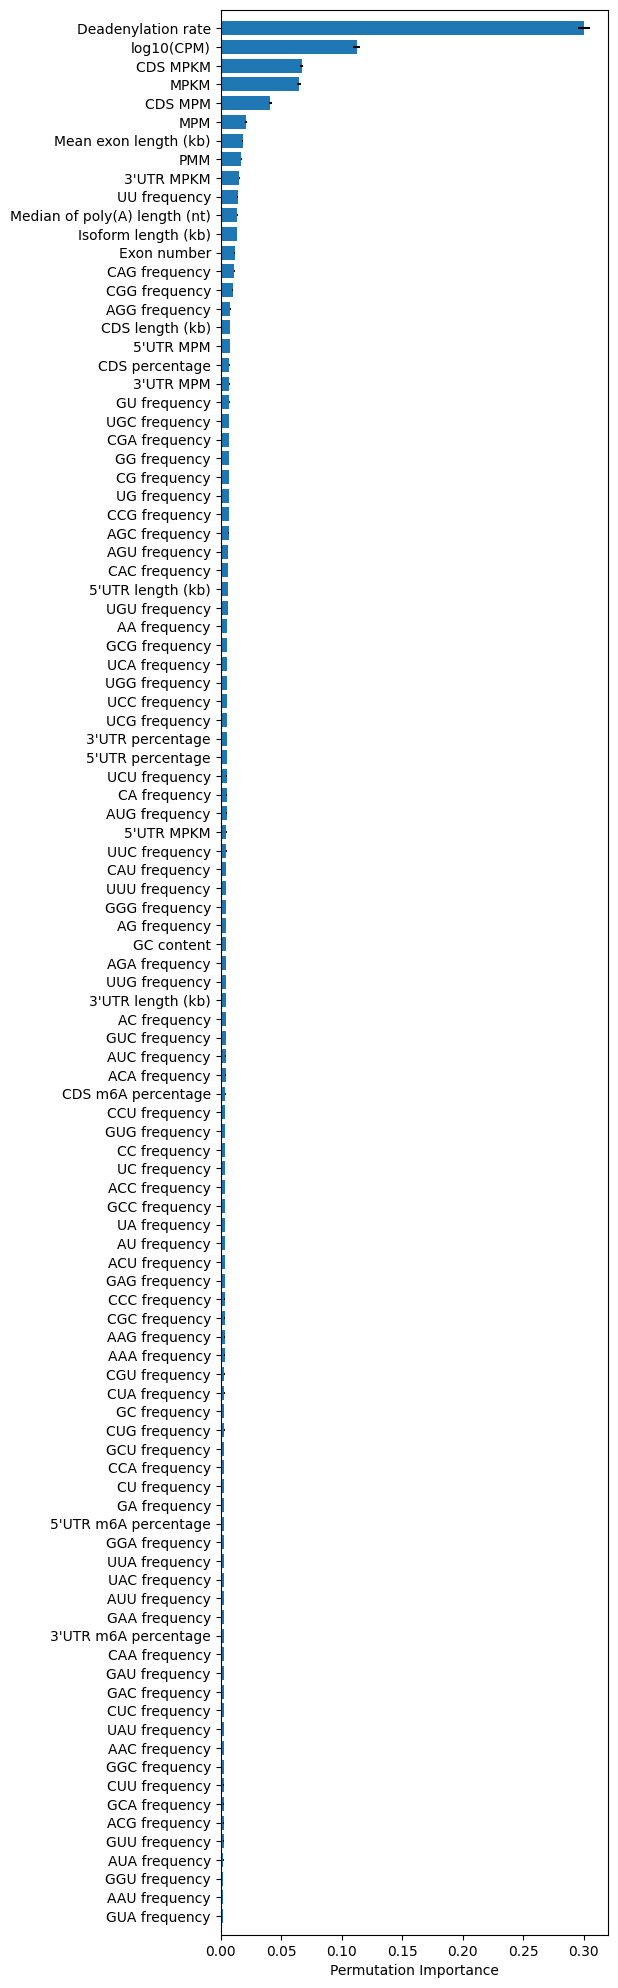

In [10]:
validate_plot(model,x_train,y_train)
from sklearn.inspection import permutation_importance
result = permutation_importance(
    model, x_train, y_train, n_repeats= 10, random_state=42, n_jobs=10
)
plt.figure(figsize=(5,25))
sorted_indices = np.argsort(result.importances_mean)
plt.barh(train.columns[1:][sorted_indices],result.importances_mean[sorted_indices],xerr=result.importances_std[sorted_indices],height=0.75)
plt.ylim(bottom=-1,top=102)
plt.yticks(fontsize=10)
plt.xlabel('Permutation Importance')

In [11]:
permutation_importance_train=pd.DataFrame()
permutation_importance_train['Feature']=train.columns[1:][sorted_indices]
permutation_importance_train['Importance']=result.importances_mean[sorted_indices]
permutation_importance_train['Std']=result.importances_std[sorted_indices]
permutation_importance_train.to_csv('./permutation_importance_train.txt',sep='\t',index=False)

Text(0.5, 0, 'Permutation Importance')

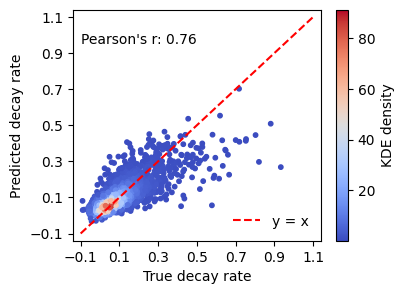

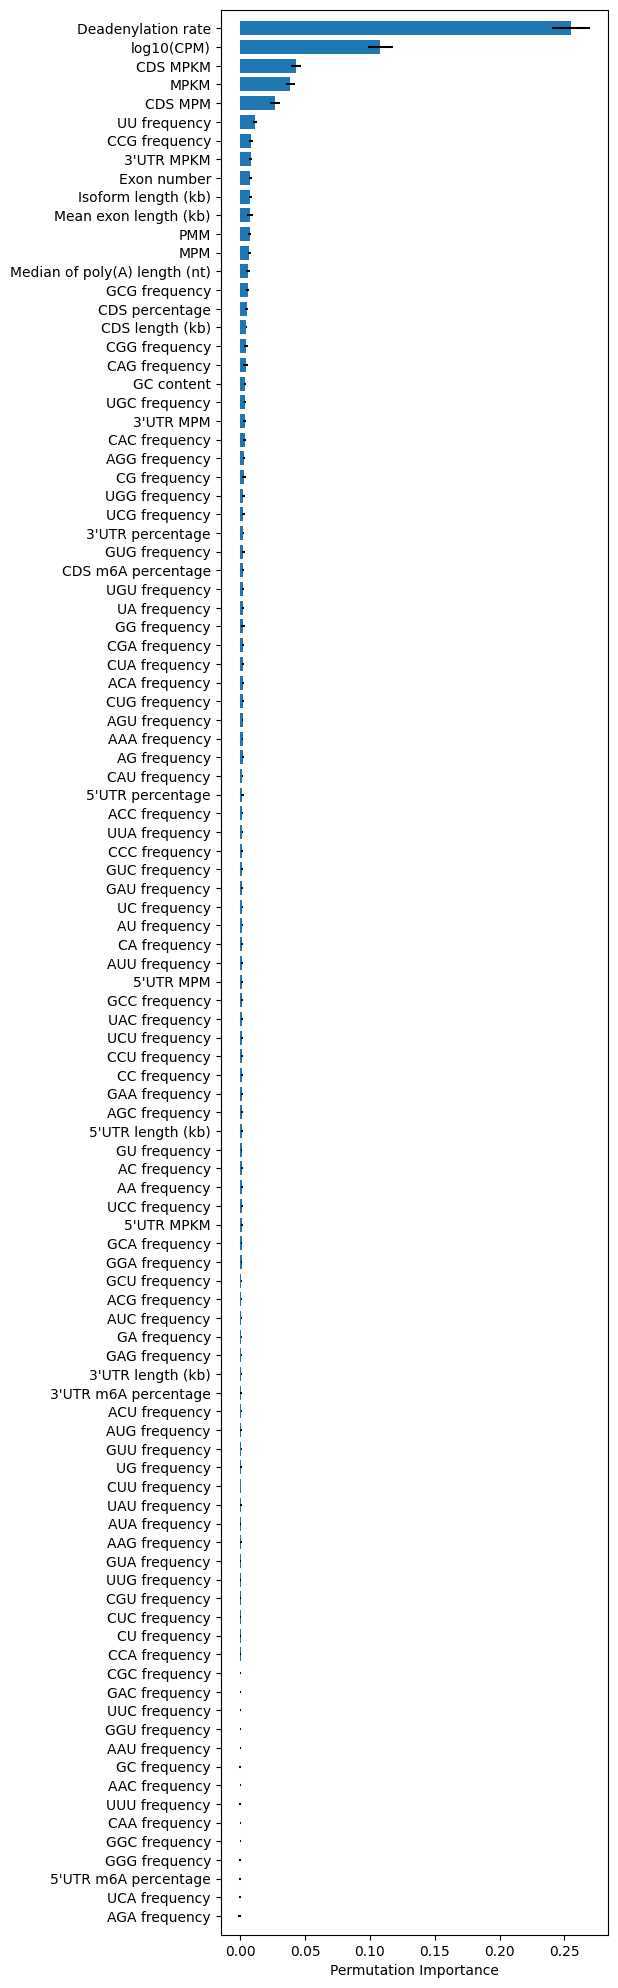

In [12]:
validate_plot(model,x_test,y_test)
from sklearn.inspection import permutation_importance
result = permutation_importance(
    model, x_test, y_test, n_repeats= 10, random_state=42, n_jobs=10
)
plt.figure(figsize=(5,25))
sorted_indices = np.argsort(result.importances_mean)
plt.barh(test.columns[1:][sorted_indices],result.importances_mean[sorted_indices],xerr=result.importances_std[sorted_indices],height=0.75)
plt.ylim(bottom=-1,top=102)
plt.yticks(fontsize=10)
plt.xlabel('Permutation Importance')


In [13]:
permutation_importance_test=pd.DataFrame()
permutation_importance_test['Feature']=train.columns[1:][sorted_indices]
permutation_importance_test['Importance']=result.importances_mean[sorted_indices]
permutation_importance_test['Std']=result.importances_std[sorted_indices]
permutation_importance_test.to_csv('./permutation_importance_test.txt',sep='\t',index=False)

In [14]:
concat_df=pd.concat([train,test])

In [15]:
features = concat_df.iloc[:,1:]
explainer = shap.TreeExplainer(model)
shap_explainer = explainer(features)
shap_values = explainer.shap_values(features)

In [16]:
shap_results=pd.DataFrame(shap_values)
shap_results.columns=features.columns
shap_results.index=features.index
shap_results.reset_index(inplace=True)
shap_results.to_csv('./shap_results.txt',sep='\t',index=False)

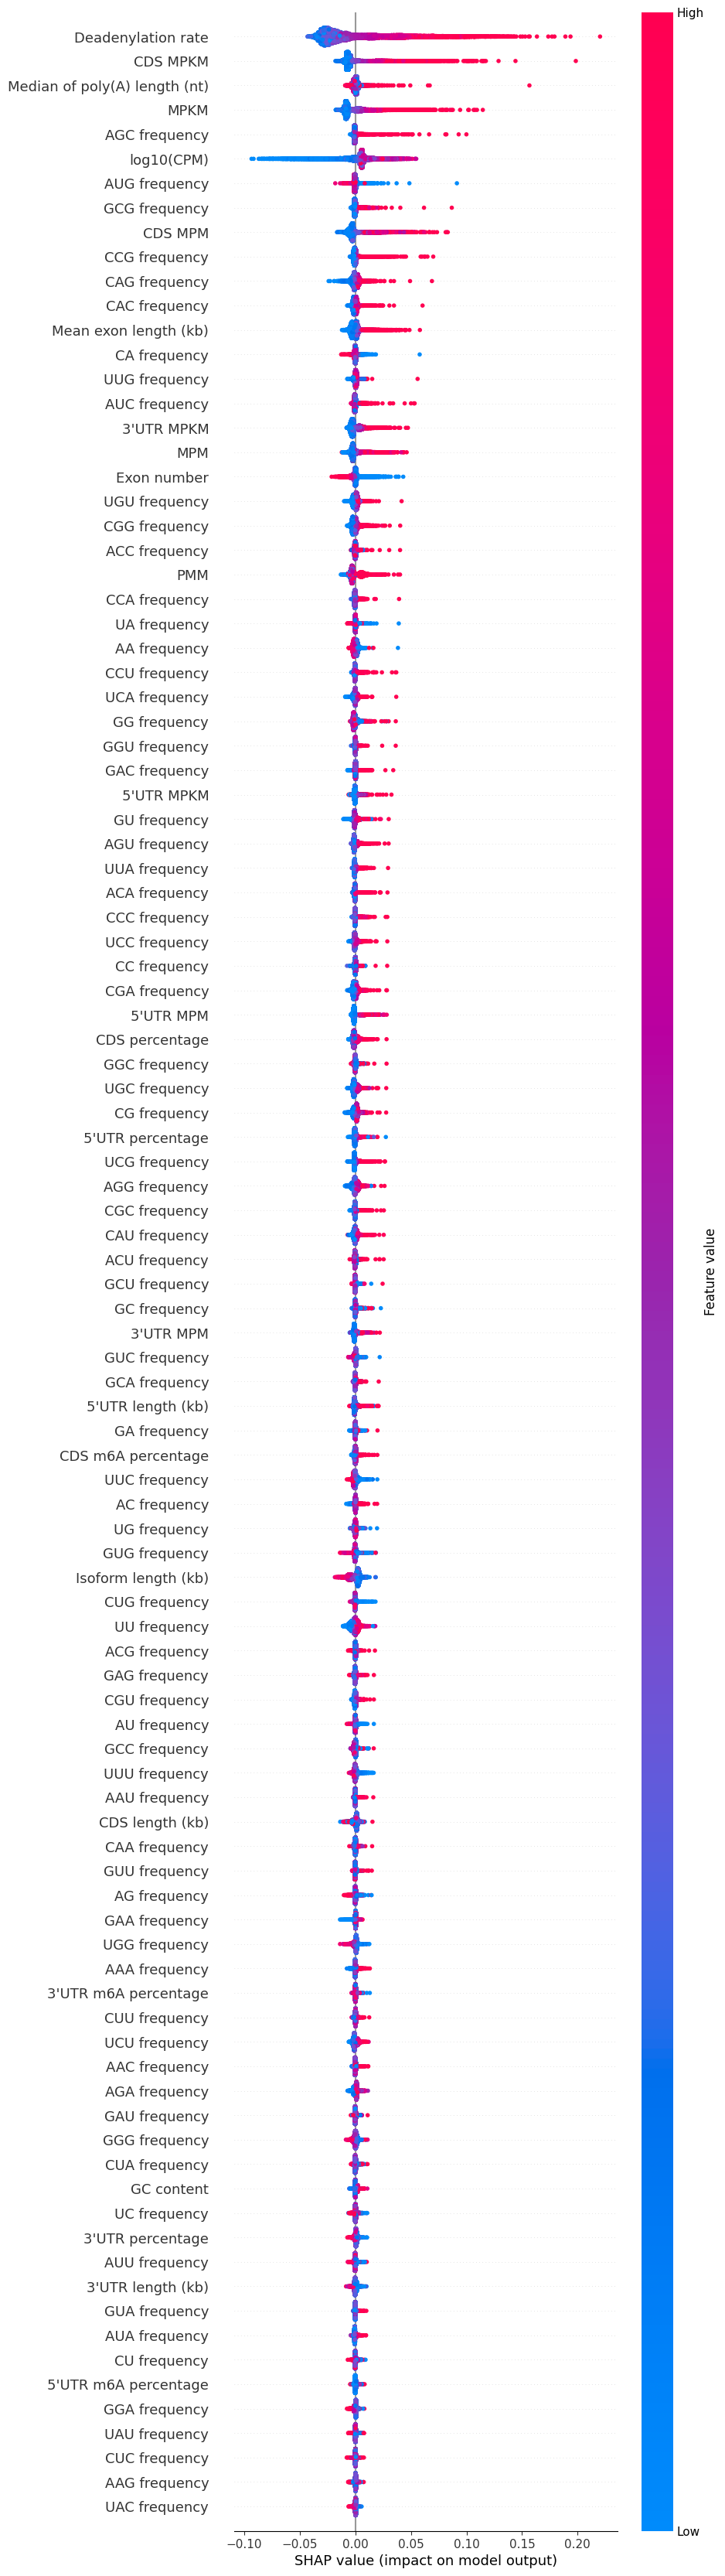

In [17]:
shap.plots.beeswarm(shap_explainer, order=shap_explainer.abs.max(0), max_display=102)